# 과제6

## 1번

- ‘deathrates.csv’ 파일에는 1950년대 중반 30개 국가의 인구 10만 명당 교통사고 사망률 데이터가 포함되어 있습니다. 아래 질문에 대한 답변 코드를 작성하시오.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

deathrates = pd.read_csv("deathrates.csv")
pop = pd.read_csv("popcities10.csv")

# 문제1 데이터프레임의 크기 출력
print("문제1 데이터프레임의 크기:", deathrates.shape)

# 문제1 데이터프레임의 처음 5개 행 출력
deathrates.head()

문제1 데이터프레임의 크기: (30, 2)


,country,death
0,Australia,17.4
1,Czechoslovakia,10.1
2,W. Germany,13.1
3,Israel,10.3
4,Norway,10.5


1-1 : hist( ) 함수를 사용하여 교통사고 사망률에 대한 히스토그램을 출력하는 코드를 작성하시오. 그래프에는 제목, x축 및 y축에 대한 레이블이 포함되어야 합니다.

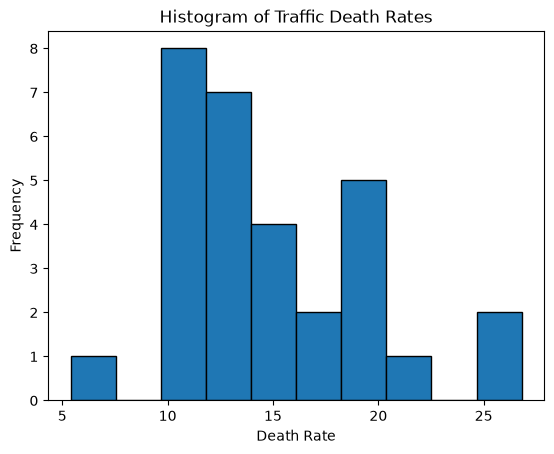

In [2]:
# 히스토그램 시각화
plt.hist(deathrates["death"], edgecolor="black")
plt.title("Histogram of Traffic Death Rates")
plt.xlabel("Death Rate")
plt.ylabel("Frequency")
plt.show()

1-2: bar( ) 함수를 사용하여 국가별 교통사고 사망률을 오름차순으로 정렬하여 막대그
래프로 나타내는 코드를 작성하시오. 그래프에는 제목, x축 및 y축의 값을 설명하는 레이블이 포함되어야 합니다.

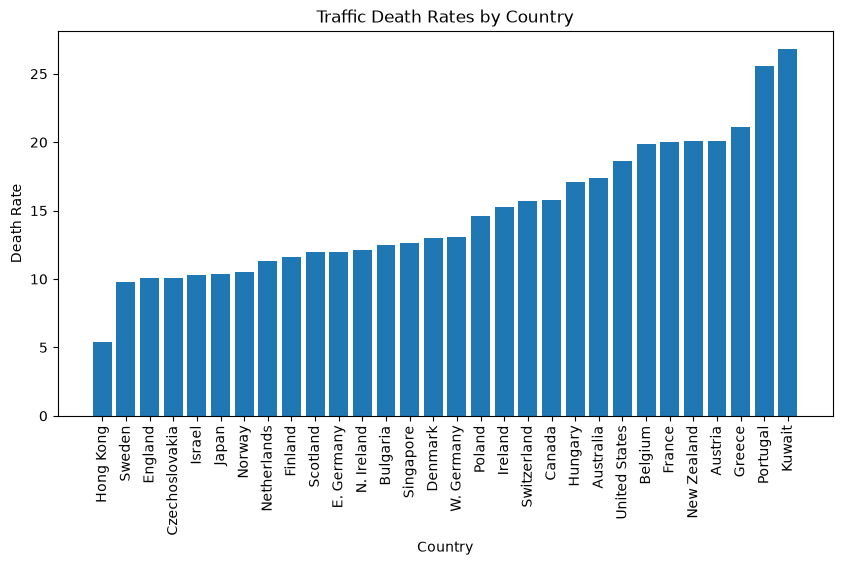

In [3]:
# 사망률 기준 오름차순 정렬
deathrates_sorted = deathrates.sort_values(by="death")

# 막대그래프 시각화
plt.figure(figsize=(10, 5))
plt.bar(deathrates_sorted["country"], deathrates_sorted["death"])
plt.title("Traffic Death Rates by Country")
plt.xlabel("Country")
plt.ylabel("Death Rate")
plt.xticks(rotation=90)
plt.show()

1-3: cut( ) 함수를 사용하여 전체 교통사고 사망률을 ‘Low’, ‘Medium’, ‘High’의 세 가지
로 분류하는 코드를 작성하시오. 분류하는 기준은 임의로 설정할 수 있습니다.

In [4]:
bin_dividers = [0, 12, 15, 30]
bin_names = ["Low", "Medium", "High"]

deathrates["level"] = pd.cut(
    deathrates["death"],
    bins=bin_dividers, 
    labels=bin_names)

# 분류 결과 및 각 범주별 개수 확인
print(deathrates.head())
print(deathrates["level"].value_counts())

          country  death   level
0       Australia   17.4    High
1  Czechoslovakia   10.1     Low
2      W. Germany   13.1  Medium
3          Israel   10.3     Low
4          Norway   10.5     Low
level
High      13
Low       11
Medium     6
Name: count, dtype: int64


1-4: (3)에서 가공된 교통사고 데이터를 사용하여 결과를 아래 그림과 같이 막대그래프
로 표현하는 코드를 작성하시오. 그래프에는 제목, x축 및 y축의 값을 설명하는 레이블이
포함되어야 합니다. *그래프 스타일은 자유롭게 설정하면 됩니다.

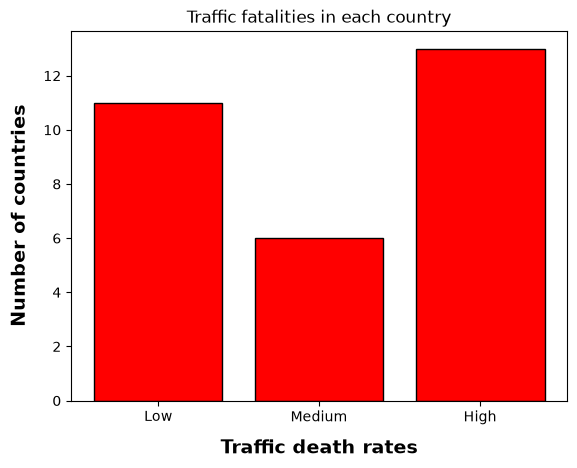

In [5]:
level_counts = deathrates["level"].value_counts(sort=False)

# 막대그래프 시각화
plt.bar(
    level_counts.index, 
    level_counts.values, 
    color="red",
    edgecolor="black")
plt.title("Traffic fatalities in each country")
plt.xlabel(
     "Traffic death rates",
     fontsize=14,
     fontweight='bold',
     labelpad=10,
     color='black')
plt.ylabel(
    "Number of countries",
    fontsize=14,
    fontweight='bold',
    labelpad=10,
    color='black')
plt.show()

## 2번

- 'popcities10.csv' 파일에는 한국 내 83개 도시의 2000년, 2005년, 2010년 인구 데이터가
포함되어 있습니다. 아래 질문에 대한 답변 코드를 작성하시오.


In [6]:
# 문제2 데이터프레임의 크기 출력
print("문제2 데이터프레임의 크기:", pop.shape)

# 문제2 데이터프레임의 처음 5개 행 출력
pop.head()

문제2 데이터프레임의 크기: (83, 6)


,rank,provinces,municipality,pop10,pop05,pop00
0,1,NaN,Seoul,9794304,9762546,9853972
1,2,NaN,Busan,3414950,3512547,3655437
2,3,NaN,Incheon,2662509,2590863,2466338
3,4,NaN,Daegu,2446418,2456016,2473990
4,5,NaN,Daejeon,1501859,1438551,1365961


2-1: plot( ) 함수를 사용하여 2000부터 2010년까지 전라북도 군산의 인구 변화와 해당
기간 평균 인구를 아래 그림과 같이 보여주는 그래프를 나타내는 코드를 작성하시오.
*그래프 스타일은 자유롭게 설정하면 됩니다.

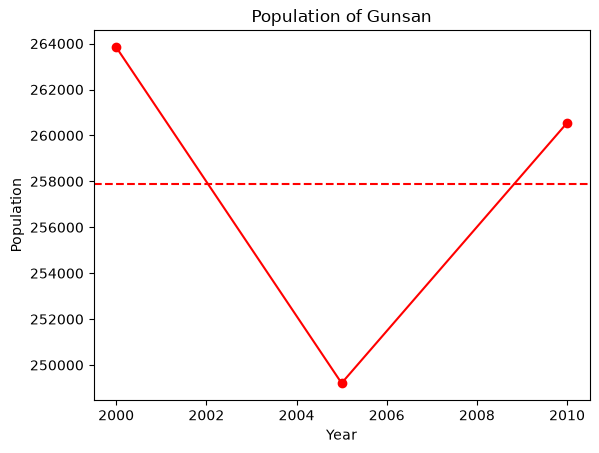

In [7]:
# 군산의 2000, 2005, 2010년 인구 데이터 추출
gunsan = pop.loc[pop["municipality"] == "Gunsan", ["pop00", "pop05", "pop10"]].iloc[0]

# 연도 리스트 및 평균 인구 계산
years = [2000, 2005, 2010]
mean_pop = gunsan.mean()

# 그래프 시각화
plt.plot(years, gunsan.values, color="red", marker="o")
plt.axhline(mean_pop, color="red", linestyle="--")
plt.title("Population of Gunsan")
plt.xlabel("Year")
plt.ylabel("Population")
plt.show()




2-2: hist( ) 함수를 사용하여 2010년 인구수 분포를 보여주는 히스토그램을 출력하는 코드를 작성하시오. 그래프에는 제목, x축 및 y축의 값을 설명하는 레이블이 포함되어야 합니다.

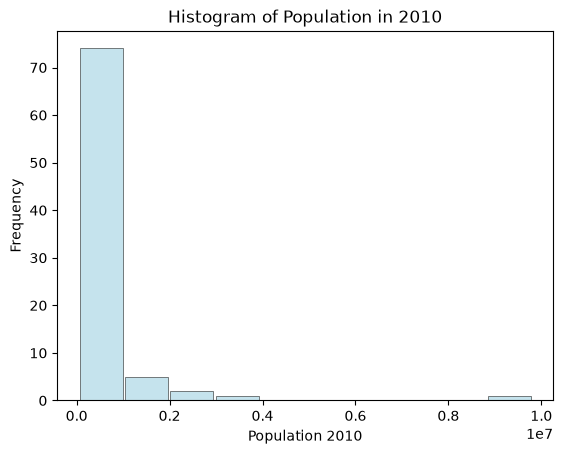

In [8]:
plt.hist(pop["pop10"],
         color="lightblue",
         alpha=0.7,
         rwidth=0.95,
         edgecolor="black",
         linewidth=0.5)
plt.title("Histogram of Population in 2010")
plt.xlabel("Population 2010")
plt.ylabel("Frequency")
plt.show()

2010년 기준 한국 83개 도시 중 70개 이상의 대다수 도시가 인구 100만 명 이하 구간에 집중되어 있으며, 우측 끝(약 979만 명)의 서울특별시를 포함한 소수의 대도시로 인해 오른쪽으로 비대칭 분포를 보인다.




2-3: 2010년을 기준으로 경기도에서 인구가 가장 많은 다섯 개 도시를 선택하고, 선택
된 도시의 인구를 막대그래프로 표현하기 위한 코드를 작성하시오. 그래프에는 제목, x축
및 y축의 값을 설명하는 레이블이 포함되어야 합니다

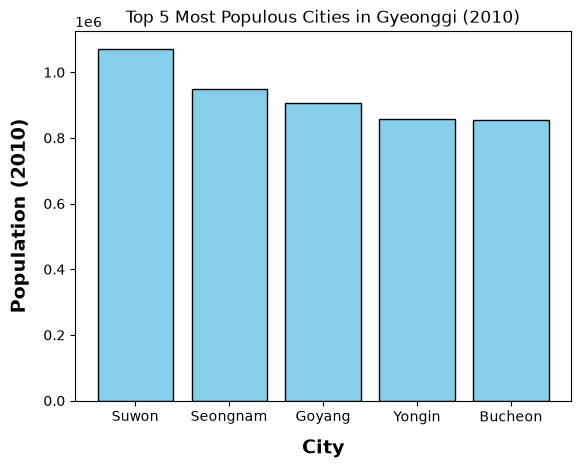

In [9]:
# 경기도 도시 필터링 
gyeonggi = pop[pop["provinces"] == "Gyeonggi"] #데이터프레임 형식
top5_gyeonggi = gyeonggi.sort_values(by="pop10", ascending=False).head(5) #데이터프레임 형식

# 막대그래프 시각화
plt.bar(
    top5_gyeonggi["municipality"],
    top5_gyeonggi["pop10"],
    color="skyblue",
    edgecolor="black")
plt.title("Top 5 Most Populous Cities in Gyeonggi (2010)")
plt.xlabel("City",
           fontsize=14,
           fontweight='bold',
           labelpad=10,
           color='black')
plt.ylabel("Population (2010)",
           fontsize=14,
           fontweight='bold',
           labelpad=10,
           color='black')
plt.show()

2-4:  2010년을 기준으로 인구가 가장 많은 다섯 개 도시를 선택하고, 해당 도시의 2000
년, 2005년, 2010년 인구를 각각 다른 색상으로 표시하는 막대그래프를 아래 그림과 같
이 나타내는 코드를 작성하시오. 그래프의 하단에는 각 도시의 이름이 표기되어야 하며,
제목, x축 및 y축 레이블, 범례도 포함되어야 합니다. *그래프 스타일은 자유롭게 설정하
면 됩니다.

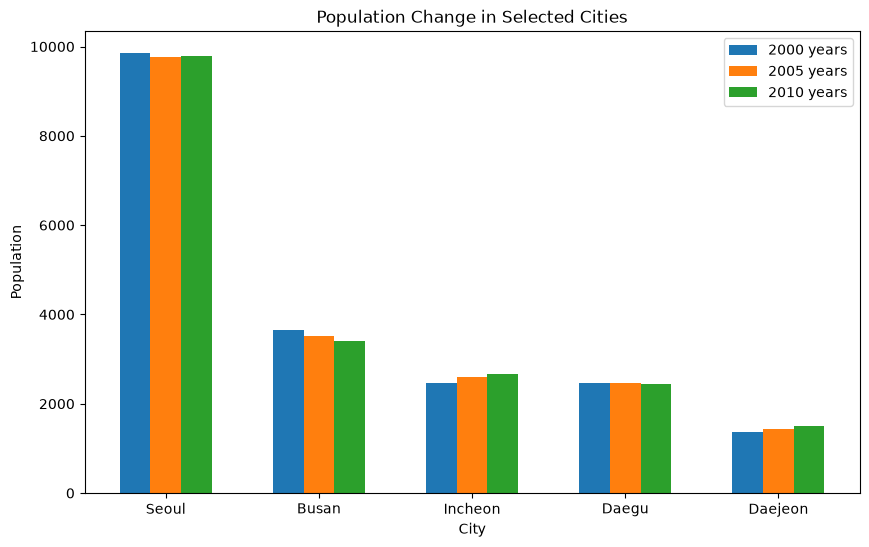

In [10]:
import numpy as np

# 2010년기준 상위 5개 도시 선택
top5 = pop.sort_values(by='pop10', ascending=False)

selected_cities = top5['municipality'][:5]
pop_2000 = top5['pop00'][:5] / 1000
pop_2005 = top5['pop05'][:5] / 1000
pop_2010 = top5['pop10'][:5] / 1000

# X축의 위치 설정
x = np.arange(len(selected_cities))

# 그래프 크기 설정
plt.figure(figsize=(10, 6))

# 막대그래프 그리기
plt.bar(x, pop_2000, width=0.2, label='2000 years')
plt.bar(x + 0.2, pop_2005, width=0.2, label='2005 years')
plt.bar(x + 0.4, pop_2010, width=0.2, label='2010 years')

# X축에 도시 이름 표시 (가운데 막대인 x + 0.2 위치에 눈금 정렬)
plt.xticks(x + 0.2, selected_cities)

# 범례 표시
plt.legend()

# 제목 및 축 라벨 추가
plt.title('Population Change in Selected Cities')
plt.xlabel('City')
plt.ylabel('Population')

# 그래프 표시
plt.show()

2-5: 2000년부터 2010년까지의 기간 동안 가장 높은 인구 증가율(%)을 가진 일곱 개의
도시를 선택하기 위한 코드를 작성하시오.

In [11]:
# 2000년 대비 2010년 인구 증가율(%) 파생 열 생성
pop["growth_rate"] = ((pop["pop10"] - pop["pop00"]) / pop["pop00"]) * 100

# 인구 증가율 기준 내림차순 정렬 후 상위 7개 도시 선택
top7_growth = pop.sort_values(by="growth_rate", ascending=False).head(7)

# 선택된 7개 도시, 증가율 확인
print(top7_growth[["municipality", "growth_rate"]])

   municipality  growth_rate
21     Hwaseong   162.802790
11       Yongin   122.686171
29         Paju    85.249085
43      Gwangju    83.307022
50         Osan    79.778466
48       Yangju    74.898548
18    Namyangju    56.061200


2-6: (5)에서 찾은 일곱 개 도시의 인구 증가율을 막대그래프 나타내는 코드를 작성하시
오. 각 도시의 이름은 막대그래프 하단에 표기되어야 하며, 제목, x축 및 y축 레이블도
포함되어야 합니다.

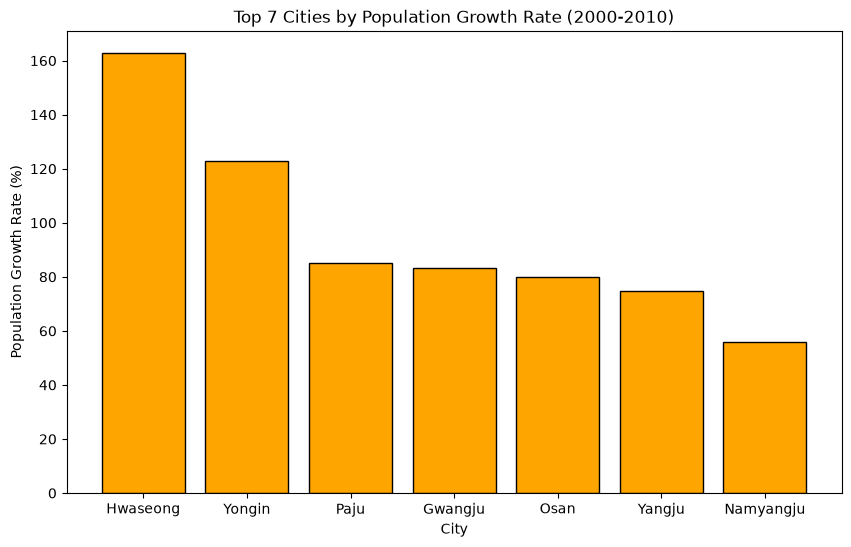

In [12]:
# 그래프 크기 설정
plt.figure(figsize=(10, 6))

# 막대그래프 시각화
plt.bar(
    top7_growth["municipality"],
    top7_growth["growth_rate"],
    color="orange",
    edgecolor="black")

# 제목 및 x축, y축 레이블 설정
plt.title("Top 7 Cities by Population Growth Rate (2000-2010)")
plt.xlabel("City")
plt.ylabel("Population Growth Rate (%)")

# 그래프 표시
plt.show()